# Income Prediction (UCI Adult Dataset)
Goal: predict whether a person earns >50K/year (binary classification).
This is an improved version of the blog code, following the module BKMs.

**Highlights**
- Missing values kept as an 'Unknown' category instead of forcing the most common value.
- Outliers detected with Tukey's IQR and LOF, analysed, and kept as genuine values.
- Stratified train/test split and a scikit-learn Pipeline (no data leakage).
- Baseline model and 5-fold cross-validation for a fair, stable evaluation.
- Recall for >50K earners improved from 0.43 (blog) to 0.86.

## 1. Importing Libraries
Loading all required libraries at the top (clean code practice).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score)
RANDOM_STATE = 42  # for reproducibility

## 2. Loading the Dataset
The raw file has no header, so column names are assigned manually.
Leading spaces are removed and '?' is converted to missing values (NaN).

In [2]:
COLUMNS = ['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation', 'relationship',
           'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']  # column names from UCI documentation (file has no header)

df = pd.read_csv('adult/adult.data',          # path to the dataset file
                 header=None,                  # first row is data, not column names
                 names=COLUMNS,                # assign our column names
                 skipinitialspace=True,        # removes the leading spaces (' ?' problem)
                 na_values='?')                # treat '?' as a real missing value

df.head()                                      # show the first 5 rows

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 3. Data Quality Check
Checking dataset size, duplicate rows, data types and missing values per column.
Missing values appear only in workclass, occupation and native_country.

In [3]:
print("Rows:", df.shape[0], "| Columns:", df.shape[1])    # dataset size
print("Duplicate rows:", df.duplicated().sum())            # repeated rows

summary = pd.DataFrame({                                   # one table with checks per column
    'Type': df.dtypes,                                      # data type
    'Missing': df.isna().sum(),                             # missing count
    'Missing %': (df.isna().mean() * 100).round(2)          # missing as percentage
})
summary

Rows: 32561 | Columns: 15
Duplicate rows: 24


,Type,Missing,Missing %
age,int64,0,0.00
workclass,str,1836,5.64
fnlwgt,int64,0,0.00
education,str,0,0.00
education_num,int64,0,0.00
marital_status,str,0,0.00
occupation,str,1843,5.66
relationship,str,0,0.00
race,str,0,0.00
sex,str,0,0.00


## 4. Class Balance
Checking the share of people earning <=50K vs >50K.
The target is imbalanced (~76% vs ~24%), so accuracy alone will be misleading.

income
<=50K    0.759
>50K     0.241
Name: proportion, dtype: float64


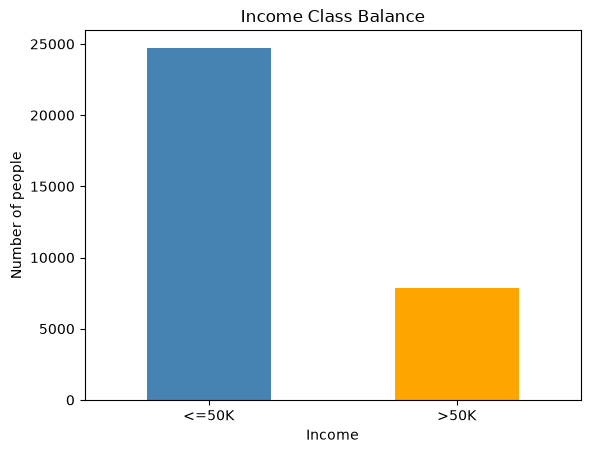

In [4]:
print(df['income'].value_counts(normalize=True).round(3))  # share of each income class (0.759 / 0.241)

df['income'].value_counts().plot(kind='bar', color=['steelblue', 'orange'])  # bar chart of people per class
plt.title('Income Class Balance')                           # chart title
plt.xlabel('Income')                                        # x-axis label
plt.ylabel('Number of people')                              # y-axis label
plt.xticks(rotation=0)                                      # keep labels horizontal
plt.show()                                                  # display the chart

## 5. Data Cleaning
Removing duplicates, converting the target to 0/1, and dropping redundant columns.
Missing values are NOT filled here; they are imputed after the train/test split to avoid data leakage.

In [5]:
df = df.drop_duplicates().reset_index(drop=True)          # remove repeated rows, reset row numbers
df['income'] = (df['income'] == '>50K').astype(int)       # target: 1 = >50K, 0 = <=50K
df = df.drop(columns=['education', 'fnlwgt'])             # education = same info as education_num; fnlwgt = census weight, not a personal trait
print("Shape after cleaning:", df.shape)                  # should be (32537, 13)

Shape after cleaning: (32537, 13)


## 6. Exploratory Data Analysis (EDA)
### 6.1 Distribution of numeric features

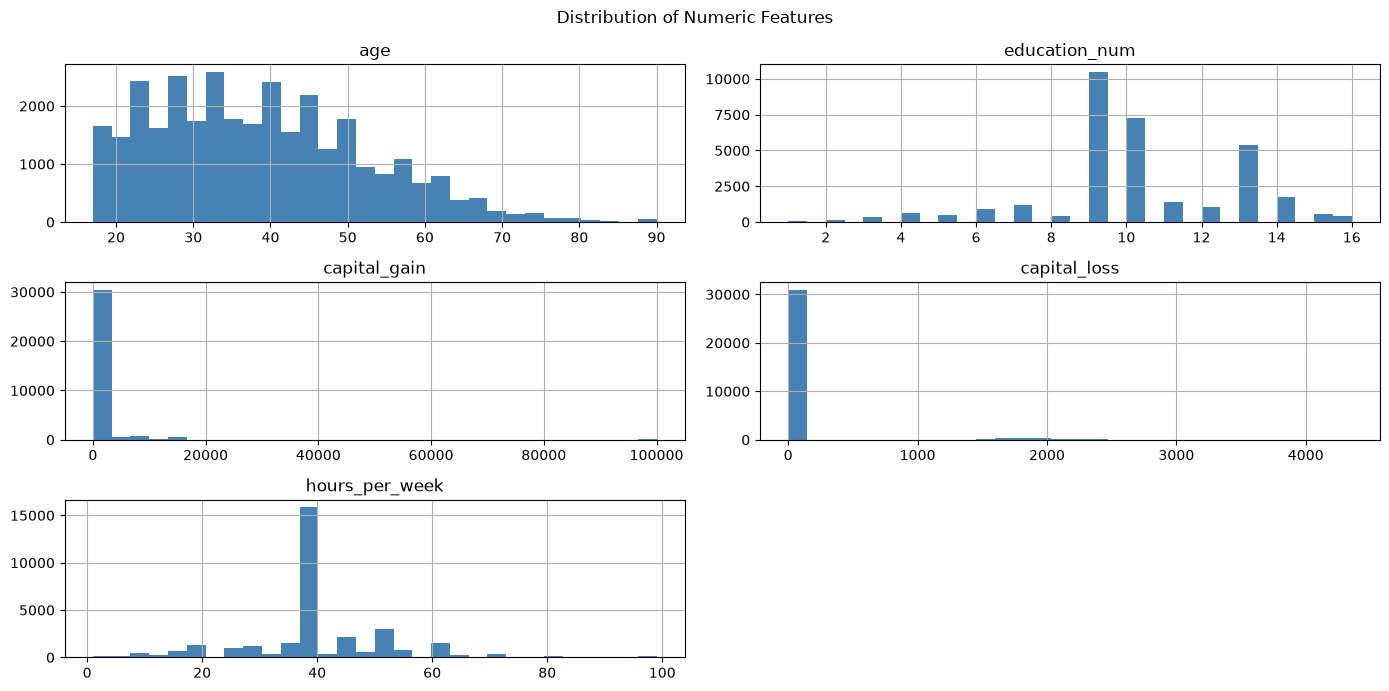

In [6]:
num_cols = df.select_dtypes('number').columns.drop('income')        # numeric features only (exclude target)
df[num_cols].hist(bins=30, figsize=(14, 7), color='steelblue')      # one histogram per numeric column
plt.suptitle('Distribution of Numeric Features')                    # overall title
plt.tight_layout()                                                  # avoid overlapping labels
plt.show()

### 6.2 Age and working hours by income group

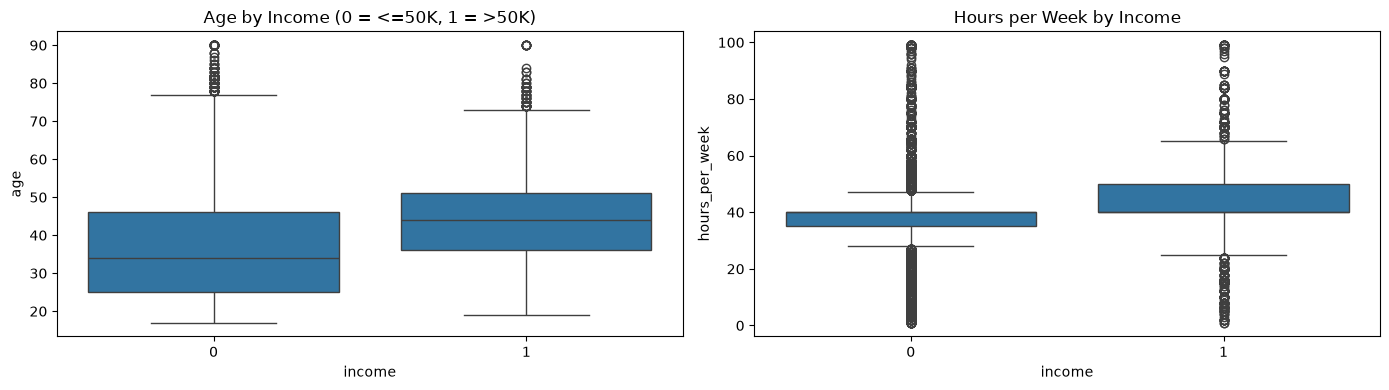

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))                     # two charts side by side
sns.boxplot(data=df, x='income', y='age', ax=axes[0])               # age spread for each income class
axes[0].set_title('Age by Income (0 = <=50K, 1 = >50K)')
sns.boxplot(data=df, x='income', y='hours_per_week', ax=axes[1])    # working hours for each income class
axes[1].set_title('Hours per Week by Income')
plt.tight_layout()
plt.show()

### 6.3 Share of high earners by marital status

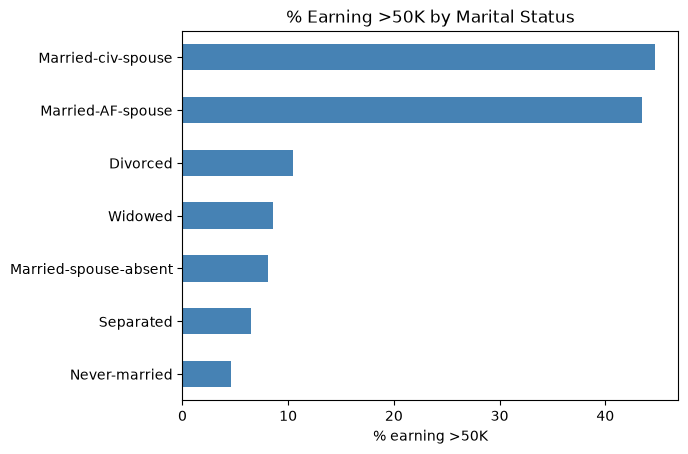

In [8]:
rate = df.groupby('marital_status')['income'].mean().sort_values() * 100    # % earning >50K per group
rate.plot(kind='barh', color='steelblue')                                   # horizontal bar chart
plt.title('% Earning >50K by Marital Status')
plt.xlabel('% earning >50K')
plt.ylabel('')
plt.show()

## 7. Anomaly Detection
### 7.1 Tukey's IQR method
A value is an outlier if it is below Q1 - 1.5*IQR or above Q3 + 1.5*IQR.

In [9]:
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])                      # 25th and 75th percentiles
    iqr = q3 - q1                                               # spread of the middle 50%
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr               # Tukey's fences
    return (series < lower) | (series > upper), lower, upper

iqr_masks = {}                                                  # store the mask for each column
for col in num_cols:
    mask, low, up = iqr_outliers(df[col])
    iqr_masks[col] = mask
    print(f"{col:15s} lower={low:8.1f}  upper={up:8.1f}  outliers={mask.sum():5d} ({mask.mean()*100:.1f}%)")

age             lower=    -2.0  upper=    78.0  outliers=  142 (0.4%)
education_num   lower=     4.5  upper=    16.5  outliers= 1193 (3.7%)
capital_gain    lower=     0.0  upper=     0.0  outliers= 2712 (8.3%)
capital_loss    lower=     0.0  upper=     0.0  outliers= 1519 (4.7%)
hours_per_week  lower=    32.5  upper=    52.5  outliers= 9002 (27.7%)


### 7.2 Local Outlier Factor (LOF)
LOF compares each point's local density with its neighbours' density.
Points in much sparser regions are flagged as outliers. Features are scaled
first because LOF is distance-based.

Note: many people share identical numeric profiles (e.g. age 30, 40 hours, no capital
gain), so sklearn warns about duplicate values. Increasing n_neighbors to 50 did not
remove it, so the warning is suppressed and the limitation is acknowledged here.

In [10]:
import warnings

X_num = StandardScaler().fit_transform(df[num_cols])            # scale so no feature dominates the distance
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.01)    # flag the most unusual 1%
with warnings.catch_warnings():                                 # hide only the duplicate-values warning (explained above)
    warnings.filterwarnings('ignore', message='Duplicate values')
    lof_mask = lof.fit_predict(X_num) == -1                     # -1 = outlier, 1 = normal
print("LOF outliers:", lof_mask.sum())

LOF outliers: 324


### 7.3 Comparing IQR and LOF

IQR outliers (any column): 12931
LOF outliers             : 324
Flagged by both          : 122


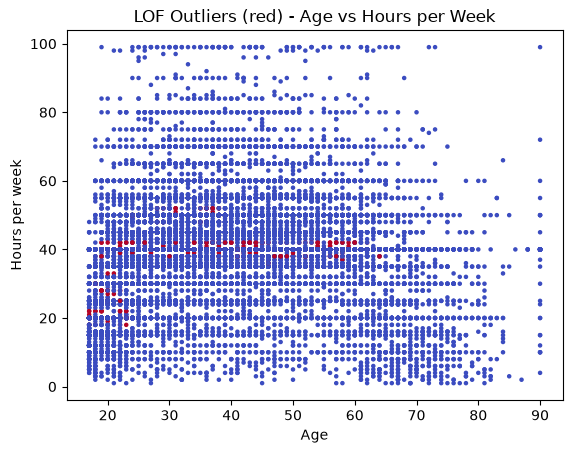

In [11]:
iqr_any = pd.DataFrame(iqr_masks).any(axis=1)                                   # outlier in at least one column (IQR)
print("IQR outliers (any column):", iqr_any.sum())
print("LOF outliers             :", lof_mask.sum())
print("Flagged by both          :", (iqr_any & lof_mask).sum())

plt.scatter(df['age'], df['hours_per_week'], c=lof_mask, cmap='coolwarm', s=5)  # red = LOF outlier
plt.title('LOF Outliers (red) - Age vs Hours per Week')
plt.xlabel('Age')
plt.ylabel('Hours per week')
plt.show()

### 7.4 Outlier decision
- IQR flagged 12,931 rows (~40%). Most of these are non-zero capital_gain/capital_loss
  values (most people have 0, so IQR = 0) and hours_per_week outside 32.5-52.5.
  IQR is not suitable for these skewed columns.
- LOF flagged 324 rows (1%) by looking at all numeric features together.
  Only 122 rows were flagged by both methods.
- LOF outliers do not stand out on the age vs hours plot because they are unusual
  in other features (e.g. capital gain).
- Decision: outliers are KEPT. They are genuine values, not data errors, and they
  carry useful information about high earners. Removing IQR outliers would delete
  ~40% of the data. Scaling limits their influence on the model.

## 8. Train/Test Split
Stratified 70/30 split so both sets keep the same 76/24 class ratio.

In [12]:
X = df.drop(columns='income')                              # features
y = df['income']                                           # target (0/1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3,                                   # 70% train, 30% test
    stratify=y,                                            # keep class ratio the same in both sets
    random_state=RANDOM_STATE)                             # reproducible split

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Share of >50K -> train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Train: (22775, 12) | Test: (9762, 12)
Share of >50K -> train: 0.241 | test: 0.241


## 9. Preprocessing Pipeline
- Numeric: median imputation (a safety step; there are no numeric gaps) + standard scaling.
- Categorical: missing values kept as an 'Unknown' category, then one-hot encoding
  (no fake order, unlike the blog's LabelEncoder). Filling with the most common value
  would invent information, e.g. labelling someone with an unknown job as 'Prof-specialty'.
- Everything is fitted on the training data only, which prevents data leakage.

In [13]:
num_features = X.select_dtypes('number').columns            # numeric columns
cat_features = X.select_dtypes(exclude='number').columns    # categorical columns

num_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),           # fill missing with median
    ('scale', StandardScaler())])                           # mean 0, std 1

cat_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='constant', fill_value='Unknown')),  # missing kept as its own category
    ('onehot', OneHotEncoder(handle_unknown='ignore'))])    # one column per category

preprocess = ColumnTransformer([
    ('num', num_pipe, num_features),
    ('cat', cat_pipe, cat_features)])

## 10. Model Training
Baseline: always predicts the majority class (<=50K), a reference point.
Logistic Regression with class_weight='balanced' to handle the 76/24 imbalance.

In [14]:
baseline = DummyClassifier(strategy='most_frequent')        # dumb model: always predicts <=50K
baseline.fit(X_train, y_train)

model = Pipeline([
    ('prep', preprocess),                                   # preprocessing
    ('clf', LogisticRegression(max_iter=1000,               # enough iterations to converge
                               class_weight='balanced',     # give more weight to the minority class
                               random_state=RANDOM_STATE))])
model.fit(X_train, y_train)                                 # fit on training data only
print("Model trained.")

Model trained.


## 11. Model Evaluation
Evaluated on the unseen test set. Because the data is imbalanced, recall, F1 and ROC-AUC are reported, not just accuracy. A baseline is included for comparison.

In [15]:
y_pred = model.predict(X_test)                             # predicted class (0/1)
y_prob = model.predict_proba(X_test)[:, 1]                 # probability of >50K
base_pred = baseline.predict(X_test)                       # baseline predictions

print("Baseline accuracy:", round((base_pred == y_test).mean(), 3))   # always-<=50K model
print("\nLogistic Regression:\n")
print(classification_report(y_test, y_pred, target_names=['<=50K', '>50K']))  # precision, recall, F1 per class
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))  # how well the model ranks >50K above <=50K

Baseline accuracy: 0.759

Logistic Regression:

              precision    recall  f1-score   support

       <=50K       0.95      0.80      0.87      7410
        >50K       0.57      0.86      0.69      2352

    accuracy                           0.81      9762
   macro avg       0.76      0.83      0.78      9762
weighted avg       0.86      0.81      0.82      9762

ROC-AUC: 0.911


### 11.1 Confusion Matrix
Shows correct predictions (diagonal) and the two error types: false positives and false negatives.

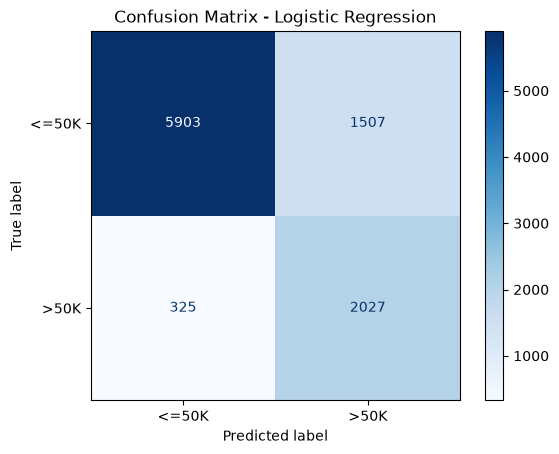

In [16]:
cm = confusion_matrix(y_test, y_pred)                      # actual vs predicted counts
ConfusionMatrixDisplay(cm, display_labels=['<=50K', '>50K']).plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

### 11.2 Cross-Validation
5-fold stratified cross-validation on the training set checks that the result is stable and not due to one lucky split.

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)  # 5 folds, same class ratio each
scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1')     # F1 on each fold
print("F1 per fold:", scores.round(3))
print("Mean F1:", round(scores.mean(), 3), "+/-", round(scores.std(), 3))

F1 per fold: [0.676 0.685 0.685 0.675 0.668]
Mean F1: 0.678 +/- 0.007


## 12. Conclusion
Comparison with the original blog (same dataset, same algorithm):

| Metric | Baseline (always <=50K) | Blog | This notebook |
|---|---|---|---|
| Recall (>50K) | 0.00 | 0.43 | 0.86 |
| F1 (>50K) | 0.00 | 0.54 | 0.69 |
| Accuracy | 0.76 | 0.82 | 0.81 |
| ROC-AUC | 0.50 | not reported | 0.91 |

Key points:
- No data leakage: imputation, encoding and scaling fitted on training data only (Pipeline).
- Missing categories kept as 'Unknown' instead of inventing values.
- One-hot encoding for categorical features instead of LabelEncoder on every column.
- Stratified split, baseline model and 5-fold cross-validation (F1 = 0.678 ± 0.007).
- Class imbalance handled with class_weight='balanced', which doubled recall.
- Accuracy is slightly lower than the blog's, an expected trade-off: the blog's model
  mostly predicted <=50K and missed more than half of the high earners.
- Outliers analysed with Tukey's IQR and LOF, and kept as genuine values.